# Orbit response

Parametric twiss example

This notebook requires knowledge of [`GTPSA.jl`](https://bmad-sim.github.io/GTPSA.jl/stable/quickstart/) because it uses `twiss` with `as_taylor_series=True`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scibmad as sb
lat = sb.julia.include("../../lattices/RCSV5S0.jl")  # the variables of the file are attributes
ring, qf_1, b0_1 = lat.ring, lat.qf_1, lat.b0_1
tw = sb.twiss(ring)
tw

Twiss:
summ:
 q1     = 43.13000170559638
 q2     = 56.21000112673147
 q3     = -0.020744708224602955
 etac   = 0.0006425524685148875
 alphac = 0.0006430166817195063

df:
5388×30 DataFrame
  Row │ index  name     kind        s         beta1     phi1         dx           x             beta2      phi2        ⋯
      │                             [m]       [m]       [2π]         [m]          [m]           [m]        [2π]        ⋯
──────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────
    1 │     1  qfs_6    Quadrupole     0.0    14.264     0.0         -7.33637e-7   0.0           0.951822   0.0        ⋯
    2 │     2  qlo_1    Drift          0.47   14.264     0.00516781  -7.33639e-7   0.0           0.951822   0.0835412
    3 │     3  bpm_1    BPM            0.525  14.117     0.00578468  -7.29799e-7   0.0           0.994778   0.0925418
    4 │     4  clo_1    Drift          0.545  14.0639    0.00601058  -7.28403e-7   0.0      

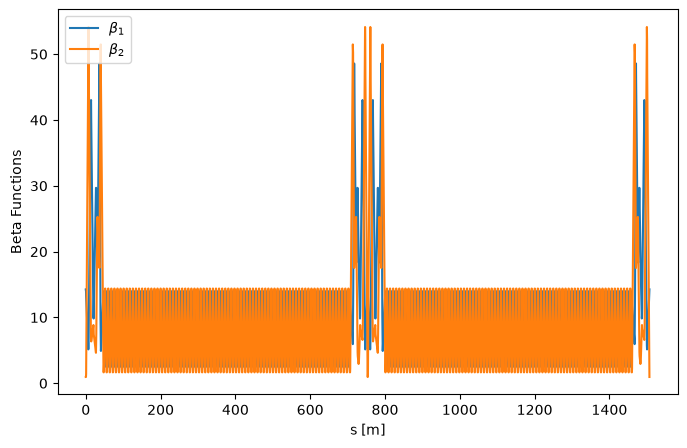

In [2]:
# Plot the betas
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tw.s, tw.beta1, label=r"$\beta_1$")
ax.plot(tw.s, tw.beta2, label=r"$\beta_2$")
ax.set(xlabel="s [m]", ylabel="Beta Functions")
ax.legend(loc="upper left");

In [3]:
# Let's see the linear closed orbit response as a function of
# e.g. qf_1 y_alignment and b0_1 tilt (2 PARAMETERS)
DPARAMS1 = sb.Descriptor(6, 1, 2, 1)  # 6 dynamic variables to 1st order, 2 parameters to 1st order
Δk = sb.params(DPARAMS1)
qf_1.y_offset = Δk[0]  # make y_offset a parameter
b0_1.tilt = Δk[1]      # make tilt a parameter
tw = sb.twiss(ring, GTPSA_descriptor=DPARAMS1, as_taylor_series=True)
tw

Twiss:
summ:
 q1     = 43.13000170559638
 q2     = 56.21000112673147
 q3     = -0.020744708224603663
 etac   = 0.0006425524685149317
 alphac = 0.0006430166817195504

df:
5388×30 DataFrame
  Row │ index  name     kind        s         beta1     phi1         dx           x                                  b ⋯
      │                             [m]       [m]       [2π]         [m]          [m]                                [ ⋯
──────┼─────────────────────────────────────────────────────────────────────────────────────────────────────────────────
    1 │     1  qfs_6    Quadrupole     0.0    14.264     0.0         -7.33637e-7  TPS64{Dynamic}:\nDescriptor(NV=6…    ⋯
    2 │     2  qlo_1    Drift          0.47   14.264     0.00516781  -7.33639e-7  TPS64{Dynamic}:\nDescriptor(NV=6…
    3 │     3  bpm_1    BPM            0.525  14.117     0.00578468  -7.29799e-7  TPS64{Dynamic}:\nDescriptor(NV=6…
    4 │     4  clo_1    Drift          0.545  14.0639    0.00601058  -7.28403e-7  TPS64{Dynamic}

In [4]:
# Closed orbit is now a Taylor series in the parameters:
# E.g. at the first element:
tw.y[1]

TPS64{GTPSA.Dynamic}:
Descriptor(NV=6, MO=1, NP=2, PO=1)
 COEFFICIENT             ORDER   EXPONENTS
-3.4019914795086181E-01    1     0 0  0 0  0 0  7^1
-3.4327120607787705E-02    1     0 0  0 0  0 0  8^1


This says that $\frac{\partial y_{co}}{\partial(\textrm{y\_offset})} = -3.4019914795086181\times 10^{-1}$ and $\frac{\partial y_{co}}{\partial(\textrm{tilt})} = -3.4327120607787705\times 10^{-2}$.
See the orbit response around the ring:

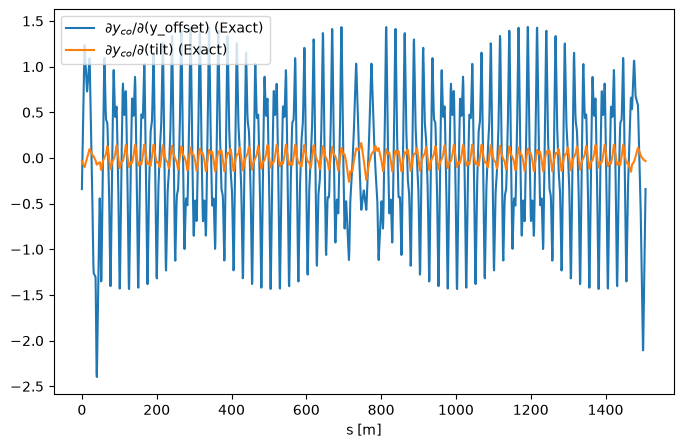

In [5]:
dy_dy_offset = [t[[0, 0, 0, 0, 0, 0, 1]] for t in tw.y]
dy_dtilt = [t[[0, 0, 0, 0, 0, 0, 0, 1]] for t in tw.y]

# Plot the response around the ring:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tw.s, dy_dy_offset, label=r"$\partial y_{co}/\partial(\mathrm{y\_offset})$ (Exact)")
ax.plot(tw.s, dy_dtilt, label=r"$\partial y_{co}/\partial(\mathrm{tilt})$ (Exact)")
ax.set(xlabel="s [m]")
ax.legend(loc="upper left");

Now let's compare to finite differencing:

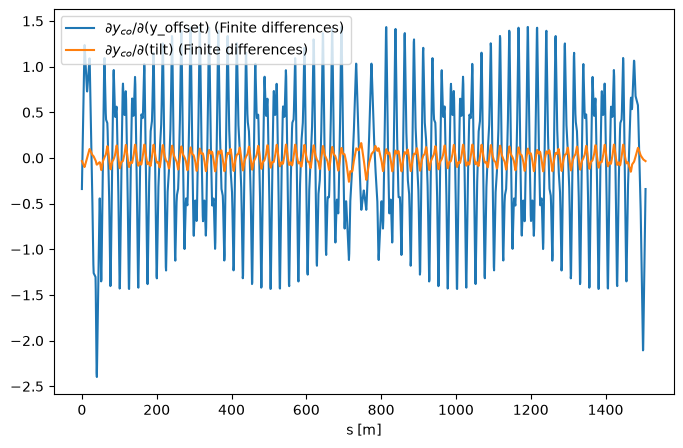

In [6]:
# First get rid of TPSA parameters in ring:
sb.scalarize(ring)

# Now set up finite differences:
step = 1e-6

# First dy/dy_offset
qf_1.y_offset = step
b0_1.tilt = 0
t = sb.twiss(ring)
dy_dy_offset_FD = np.asarray(t.y)/step

# Now dy/dtilt:
qf_1.y_offset = 0
b0_1.tilt = step
t = sb.twiss(ring)
dy_dtilt_FD = np.asarray(t.y)/step

# And plot the response around the ring:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(t.s, dy_dy_offset_FD, label=r"$\partial y_{co}/\partial(\mathrm{y\_offset})$ (Finite differences)")
ax.plot(t.s, dy_dtilt_FD, label=r"$\partial y_{co}/\partial(\mathrm{tilt})$ (Finite differences)")
ax.set(xlabel="s [m]")
ax.legend(loc="upper left");

Finite differences is usually ok for first order derivatives, but suffers significant error beyond that. Thanks to SciBmad's automatic differentiability, we can exactly compute the nonlinear derivatives. Simply specify a higher order for the GTPSA `Descriptor` and follow the same procedure above.